# Drawing, Text and GUI Events

Almost every computer-vision result is communicated by drawing on an image: bounding boxes, labels, keypoints and overlays. This notebook covers the drawing functions, adding text, working with mouse events and trackbars conceptually, and building small interactive-style tools in a headless-safe way.

## Setup

We import OpenCV (`cv2`), NumPy and Matplotlib. In these notebooks images are displayed with Matplotlib so the code runs everywhere, including servers without a screen. The classic OpenCV window functions are explained where they belong, with example code you can run on your own machine.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

def show(image, title="", cmap=None):
    """Display a BGR (or single-channel) image with matplotlib - works in any environment."""
    if len(image.shape) == 2:
        plt.imshow(image, cmap=cmap or "gray")
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


OpenCV version: 4.10.0


## Drawing lines, rectangles and circles

All drawing functions modify the image **in place**. Colours are BGR tuples, thickness is in pixels, and thickness `-1` fills the shape. Rectangles take opposite corners; circles take a centre and radius.

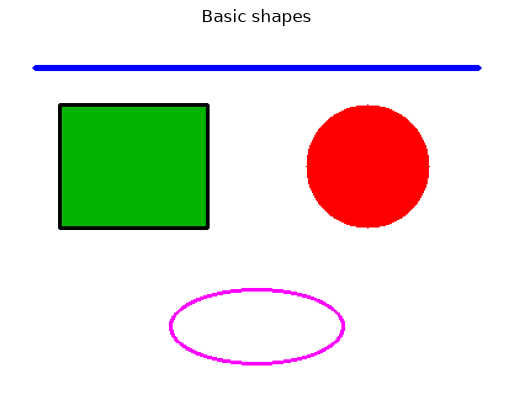

In [2]:
canvas = np.full((300, 400, 3), 255, np.uint8)
cv2.line(canvas, (20, 30), (380, 30), (255, 0, 0), 3)
cv2.rectangle(canvas, (40, 60), (160, 160), (0, 180, 0), -1)
cv2.rectangle(canvas, (40, 60), (160, 160), (0, 0, 0), 2)
cv2.circle(canvas, (290, 110), 50, (0, 0, 255), -1)
cv2.ellipse(canvas, (200, 240), (70, 30), 0, 0, 360, (255, 0, 255), 2)
show(canvas, "Basic shapes")

## Polylines and filled polygons

`cv2.polylines` draws connected points; `cv2.fillPoly` fills them. Points must be an int32 array shaped (N, 1, 2) - the reshape below is the standard pattern.

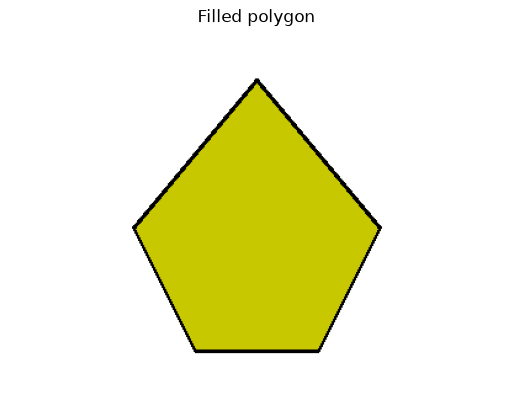

In [3]:
canvas2 = np.full((300, 400, 3), 255, np.uint8)
pts = np.array([[200, 40], [300, 160], [250, 260], [150, 260], [100, 160]], np.int32)
cv2.fillPoly(canvas2, [pts.reshape(-1, 1, 2)], (0, 200, 200))
cv2.polylines(canvas2, [pts.reshape(-1, 1, 2)], True, (0, 0, 0), 2)
show(canvas2, "Filled polygon")

## Adding text with putText

`cv2.putText` draws text at a bottom-left origin. Choose a font such as `FONT_HERSHEY_SIMPLEX`, a scale, colour and thickness. For a label above a box, draw a filled rectangle first and put white text on it - exactly how detection labels are drawn.

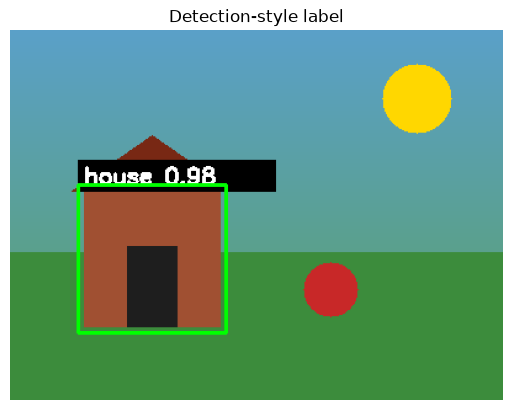

In [4]:
img = cv2.imread("../assets/test_image.png")
cv2.rectangle(img, (55, 105), (215, 130), (0, 0, 0), -1)
cv2.putText(img, "house 0.98", (60, 124), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)
cv2.rectangle(img, (55, 125), (175, 245), (0, 255, 0), 2)
show(img, "Detection-style label")

## Mouse events - the idea and the callback pattern

On a desktop you register a callback with `cv2.setMouseCallback(window_name, callback)`. The callback receives an event code such as `cv2.EVENT_LBUTTONDOWN` plus x, y coordinates. The pattern below is shown as a function and tested by calling it directly with fake coordinates - the same logic a real mouse click would trigger.

Recorded clicks: [(50, 60), (200, 120)]


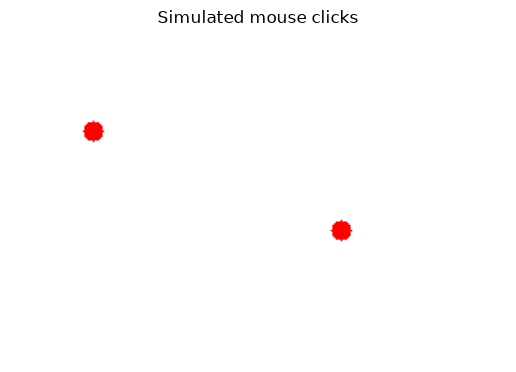

In [5]:
clicks = []
def on_mouse(event, x, y, flags, param):
    if event == cv2.EVENT_LBUTTONDOWN:
        clicks.append((x, y))
        cv2.circle(param, (x, y), 6, (0, 0, 255), -1)

board = np.full((200, 300, 3), 255, np.uint8)
on_mouse(cv2.EVENT_LBUTTONDOWN, 50, 60, 0, board)    # simulated click
on_mouse(cv2.EVENT_LBUTTONDOWN, 200, 120, 0, board)  # simulated click
print("Recorded clicks:", clicks)
show(board, "Simulated mouse clicks")
# On your own machine:
# cv2.namedWindow("board"); cv2.setMouseCallback("board", on_mouse, board)

## Trackbars - interactive parameter control

Trackbars are sliders attached to a window, created with `cv2.createTrackbar(name, window, value, max, callback)` and read with `cv2.getTrackbarPos`. They are the standard way to tune thresholds live. The headless-safe equivalent is to sweep the parameter in code and view the results side by side, as done here with a threshold value.

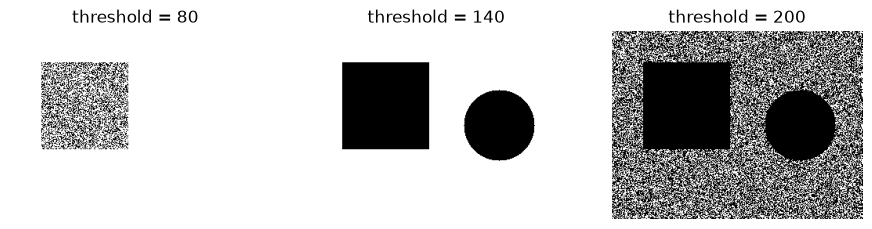

In [6]:
gray = cv2.cvtColor(cv2.imread("../assets/noisy_image.png"), cv2.COLOR_BGR2GRAY)
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, t in zip(axes, (80, 140, 200)):
    _, binary = cv2.threshold(gray, t, 255, cv2.THRESH_BINARY)
    ax.imshow(binary, cmap="gray"); ax.set_title(f"threshold = {t}"); ax.axis("off")
plt.show()

## Alpha blending and overlays

`cv2.addWeighted(img1, alpha, img2, beta, gamma)` blends two images. It is used for watermark overlays, heatmap overlays and transparent annotations. Both images must have the same size and type.

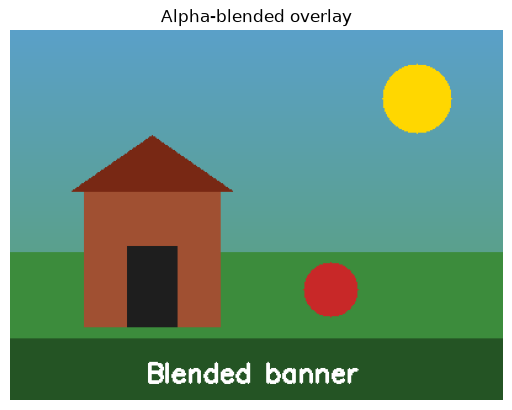

In [7]:
base = cv2.imread("../assets/test_image.png")
overlay = base.copy()
cv2.rectangle(overlay, (0, 250), (400, 300), (0, 0, 0), -1)
blended = cv2.addWeighted(base, 0.6, overlay, 0.4, 0)
cv2.putText(blended, "Blended banner", (110, 285), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
show(blended, "Alpha-blended overlay")

## Key Points

- Drawing functions modify the image in place - work on a copy if you need the original.
- Thickness -1 fills a shape; points for polygons must be int32 with shape (N, 1, 2).
- Detection labels = filled rectangle + putText in a contrasting colour.
- Mouse callbacks receive event, x, y; trackbars are read with getTrackbarPos.
- addWeighted blends two same-sized images with weights alpha and beta.

## Mini Task

1. Create a white 400x400 canvas and draw a simple house: square body, triangle roof, circle window.
2. Write your initials on the canvas with putText.
3. Simulate two mouse clicks with the callback pattern and draw a line between the clicked points.